# Chemical Space and Clustering

Shared notebook rebuilt from the RadioF version. It keeps the general workflow of the original notebook, but reuses the RadioF plotting fixes and adds optional UMAP screening, HDBSCAN screening, and descriptor heatmaps.

In [1]:

import importlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap.plot
from numba.core.errors import NumbaWarning
from sklearn.preprocessing import StandardScaler

import clustering_functions as cf
importlib.reload(cf)

warnings.simplefilter('ignore', category=NumbaWarning)


/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for th

In [2]:
# shared figure defaults (also used by screening figures)
fig_size_default = (6, 6)
marker_size_default = 45
marker_alpha_default = 0.75
fig_font_size = 12
fig_title_size = 14
fig_cmap = 'viridis'

# Read in Data

In [3]:

feature_input_file = './data/sample_input' #a file with smiles, descriptors and IDs
feature_sheet_name = 'Sheet1'
feature_start_column = 5 #column where descriptors start, 0-indexed
feature_header_rows = 1 #adjust as needed

feature_id_column_name = 'Compound_Name'
feature_smiles_column_name = 'smiles'
feature_type_column_name = 'type' #if you do not need subgroups enter: None (not 'None')

#if you want to visualize data by a response variable
response_input_file = None
response_column_name = None
response_header_rows = None
response_id_column_name = None

#_______________________________________________________________________________
#_______________________________________________________________________________

feature_input_df = pd.read_excel(feature_input_file + '.xlsx', sheet_name=feature_sheet_name, header=feature_header_rows)
feature_input_df_shape = feature_input_df.shape
# Treat all columns except SMILES as required and remove rows with missing required values.
allowed_empty = [feature_smiles_column_name]
feature_input_df.dropna(subset=[col for col in feature_input_df.columns if col not in allowed_empty], inplace=True)
feature_input_df.reset_index(drop=True, inplace=True)
feature_input_df_nona = feature_input_df.shape
removed_rows = feature_input_df_shape[0] - feature_input_df_nona[0]

if removed_rows:
    print('Some rows with missing values were removed')
print('Original number of datapoints: ', feature_input_df_shape[0])
print('New number of datapoints: ', feature_input_df_nona[0])

feature_df = feature_input_df.iloc[:, feature_start_column:]
plotting_data = feature_input_df.copy()

ID = plotting_data[feature_id_column_name]
if feature_smiles_column_name is not None:
    smiles = plotting_data[feature_smiles_column_name]
else:
    plotting_data['smiles'] = 'not available'
    smiles = plotting_data['smiles']

if feature_type_column_name is not None:
    type_column = plotting_data[feature_type_column_name]
    type_column.reset_index(drop=True, inplace=True)
else:
    type_column = None

if response_input_file is not None:
    response_column = plotting_data[response_column_name]
    response_input = pd.read_excel(response_input_file + '.xlsx', sheet_name=feature_sheet_name, header=response_header_rows)
    response_df = response_input.filter(items=[response_id_column_name, response_column_name])
    plotting_data = pd.merge(response_df, plotting_data, on=response_id_column_name)
else:
    response_column = None


Original number of datapoints:  450
New number of datapoints:  450


In [4]:

# Remove one descriptor from each pair whose absolute Pearson correlation exceeds the threshold.
# Because the upper triangle is scanned, the retained descriptor depends on column order.
threshold = 0.7
print(f'Shape of descriptors file before removing parameters with |r| > {threshold} :', feature_df.shape)
df_corr = feature_df.corr()
df_not_correlated = ~(df_corr.mask(np.tril(np.ones([len(df_corr)] * 2, dtype=bool))).abs() > threshold).any()
un_corr_idx = df_not_correlated.loc[df_not_correlated[df_not_correlated.index] == True].index
feature_df = feature_df[un_corr_idx]
print(f'Shape of descriptors file after removing parameters with |r| > {threshold} : ', feature_df.shape)


Shape of descriptors file before removing parameters with |r| > 0.7 : (450, 290)
Shape of descriptors file after removing parameters with |r| > 0.7 :  (450, 40)


In [5]:

# Standardize each retained descriptor to zero mean and unit variance before dimensionality reduction.
scaler = StandardScaler()
features_scaled = scaler.fit_transform(feature_df)


# Perform Dimensionality Reduction if Needed

### UMAP

#### Screen UMAP parameters (optional)

Compare neighborhood sizes and minimum distances. Then enter the chosen settings into **Run and Plot UMAP**.

/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/pbianchi/micromamba

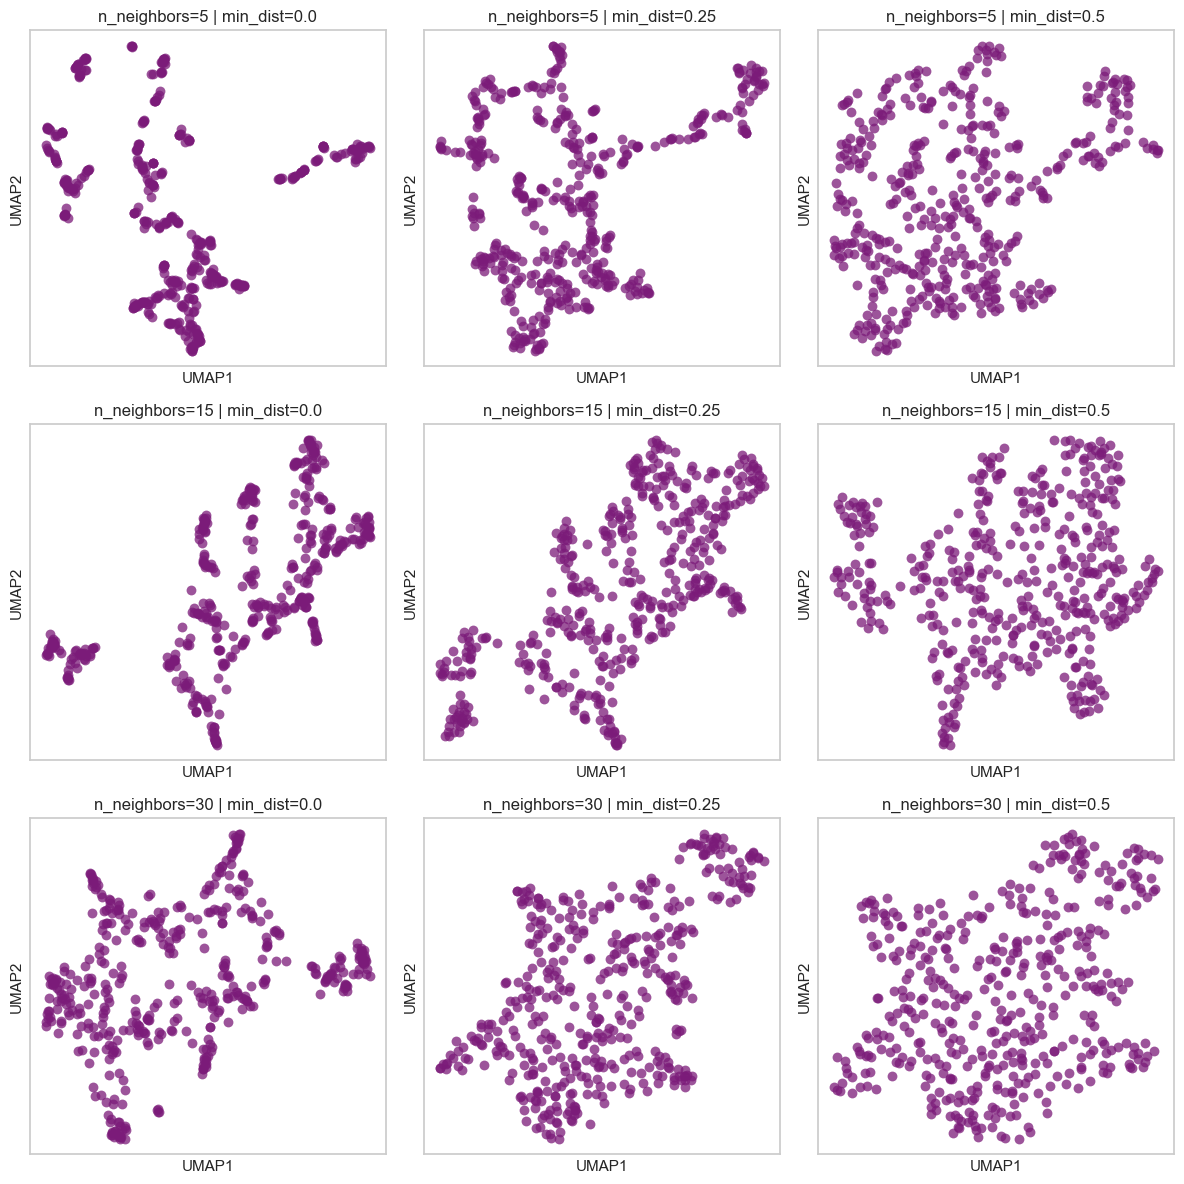

In [6]:

umap_neighbors = [5, 15, 30]
umap_min_dists = [0.0, 0.25, 0.5]
umap_metric = 'euclidean'
umap_seed = 42
screen_umap_save_plot = False
screen_umap_filename = 'umap_parameter_screen.png'

umap_screen_fig, umap_screen_axes = cf.screen_umap_parameters(
    features=features_scaled,
    n_neighbors_values=umap_neighbors,
    min_dist_values=umap_min_dists,
    metric=umap_metric,
    random_state=umap_seed,
    fig_size=(4, 4),
    marker_size=50,
    alpha=marker_alpha_default,
    color='#7B1B79',
    save_plot=screen_umap_save_plot,
    plot_filename=screen_umap_filename
)


#### Run and Plot UMAP

/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP coordinates exported to umap_digits_sample_coordinates.xlsx
Plot saved as umap_digits_sample_plot.png


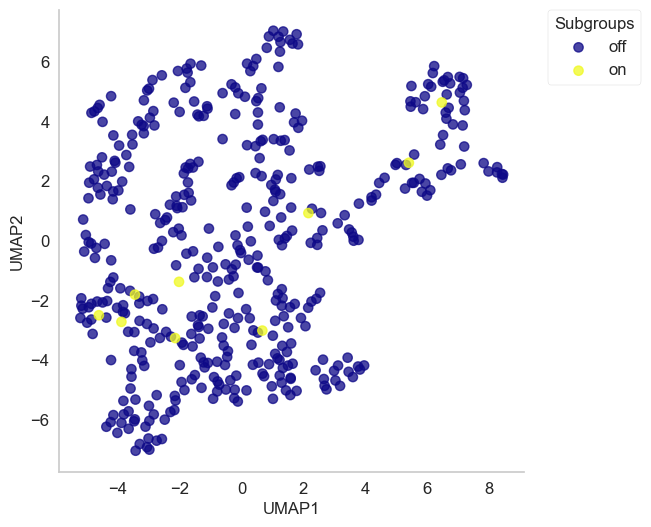

In [7]:

feature_set = features_scaled
export_to_excel = True
save_plot_as_png = True
excel_file_name = 'umap_digits_sample_coordinates.xlsx'
plot_file_name = 'umap_digits_sample_plot.png'
fig_size = fig_size_default

#### ------ Set UMAP Hyperparameters --------
# FOR MORE INFO ON UMAP HYPERPARAMETERS: pair-code.github.io/understanding-umap/

n_neighbors = 5
minimum_distance = 0.5
distance_metric = 'euclidean'
random_state = 42

#### --- Choose plot parameters --- ###
alpha = marker_alpha_default
color = '#7B1B79'
edge_color = None
marker = 'o'
size = marker_size_default
ax_font_size = fig_font_size
title_font_size = fig_title_size
plot_title = None

# If you want to plot subsets of data points
subgroup = True
subgroup_column_name = 'type'
subgroup_palette = 'plasma'
color_dictionary = None

# If you want to plot UMAP by a response variable - will override subgroup if heatmap=True
heatmap = False
response_column = None
heatmap_palette = 'plasma'

# If you want to vary marker size, type or alpha by a variable
size_col_name = None
min_marker_size = 5
max_marker_size = 100

marker_col_name = None
marker_dict = None

alpha_col_name = None
min_alpha = 0.3
max_alpha = 1.0
#_______________________________________________________________________________
#_______________________________________________________________________________

umap_df = cf.dim_reduction_umap(
    feature_set, 'UMAP1', 'UMAP2', id_column=ID, smiles_column=smiles,
    excel_filename=excel_file_name, n_neighbors=n_neighbors,
    min_dist=minimum_distance, n_components=2, distance_metric=distance_metric,
    random_state=random_state, excel_export=export_to_excel
)

umap_fig, umap_ax = cf.plot_chemical_space(
    df=umap_df, x='UMAP1', y='UMAP2', fig_size=fig_size, xlabel='UMAP1', ylabel='UMAP2',
    marker_size=size, marker_color=color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
    marker_edge_width=1, title=plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
    fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup,
    subgroup_column_name=subgroup_column_name, subgroup_palette=subgroup_palette,
    category_dict=color_dictionary, heatmap=heatmap, response_column_name=response_column,
    heatmap_palette=heatmap_palette, size_col_name=size_col_name, min_size=min_marker_size,
    max_size=max_marker_size, alpha_col_name=alpha_col_name, min_alpha=min_alpha,
    max_alpha=max_alpha, marker_col=marker_col_name, marker_dict=marker_dict,
    input_df=feature_input_df
)


### TSNE

#### Run and Plot TSNE

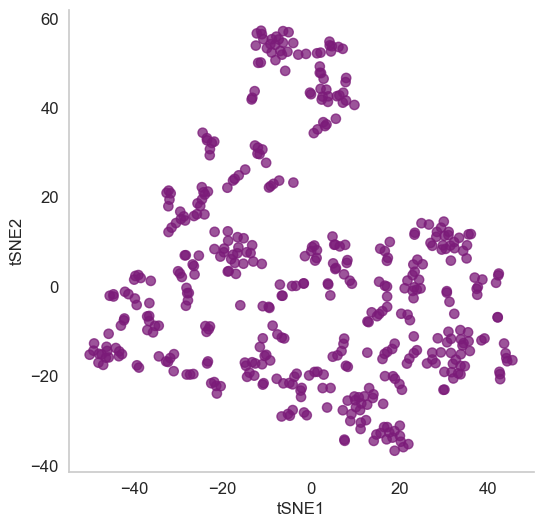

In [8]:

feature_set = features_scaled
export_to_excel = False
save_plot_as_png = False
excel_file_name = 'tsne_digits_coordinates.xlsx'
plot_file_name = 'tsne_digits_plot.png'
fig_size = fig_size_default

# tune hyperparameters
perplexity = 10
init = 'pca'
learning_rate = 'auto'
distance_metric = 'euclidean'
random_state = 42

#### --- Choose plot parameters --- ###
alpha = marker_alpha_default
color = '#7B1B79'
edge_color = None
marker = 'o'
size = marker_size_default
ax_font_size = fig_font_size
title_font_size = fig_title_size
plot_title = None

subgroup = False
subgroup_column_name = None
subgroup_palette = None
color_dictionary = None

heatmap = False
response_column = None
heatmap_palette = 'plasma'

size_col_name = None
min_marker_size = 5
max_marker_size = 100
marker_col_name = None
marker_dict = None
alpha_col_name = None
min_alpha = 0.3
max_alpha = 1.0
#_______________________________________________________________________________
#_______________________________________________________________________________

tsne_df = cf.dim_reduction_tsne(
    feature_set, 'tSNE1', 'tSNE2', id_column=ID, smiles_column=smiles,
    excel_filename=excel_file_name, n_components=2, perplexity=perplexity,
    learning_rate=learning_rate, init=init, random_state=random_state,
    distance_metric=distance_metric, export_excel=export_to_excel
)

tsne_fig, tsne_ax = cf.plot_chemical_space(
    df=tsne_df, x='tSNE1', y='tSNE2', fig_size=fig_size, xlabel='tSNE1', ylabel='tSNE2',
    marker_size=size, marker_color=color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
    marker_edge_width=1, title=plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
    fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup,
    subgroup_column_name=subgroup_column_name, subgroup_palette=subgroup_palette,
    category_dict=color_dictionary, heatmap=heatmap, response_column_name=response_column,
    heatmap_palette=heatmap_palette, size_col_name=size_col_name, min_size=min_marker_size,
    max_size=max_marker_size, alpha_col_name=alpha_col_name, min_alpha=min_alpha,
    max_alpha=max_alpha, marker_col=marker_col_name, marker_dict=marker_dict,
    input_df=feature_input_df
)


### PCA

#### Run and Plot PCA

Total variance explained by PCs: 32.2 %

Percentage of explained variance per principal component:
PC1   21.4%
PC2   10.8%


,PC1,PC2
HOMO_Boltz,0.045256,0.056153
HOMO_Boltz_stdev,0.212195,0.080089
LUMO_Boltz,0.054656,-0.250850
LUMO_Boltz_stdev,0.187385,0.058693
η_Boltz_stdev,0.209311,-0.072745
polar_aniso(Debye)_Boltz_stdev,0.171979,0.010037
dipole(Debye)_Boltz,0.065107,0.125615
dipole(Debye)_Boltz_stdev,0.159698,0.198454
volume(Bohr_radius³/mol)_Boltz_stdev,0.187163,0.049706
SASA_sphericity_Boltz_stdev,0.238921,-0.092405


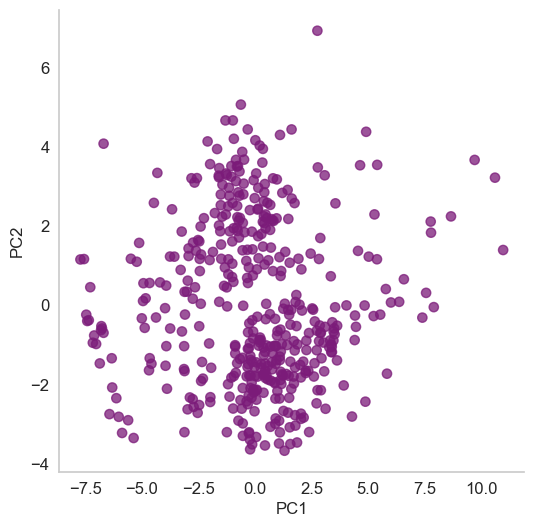

In [9]:

feature_set = pd.DataFrame(features_scaled, columns=feature_df.columns)
export_to_excel = False
save_plot_as_png = False
pc_coords_filename = 'pca_coordinates.xlsx'
pc_contrib_filename = 'pca_feature_contributions.xlsx'
plot_file_name = 'pca_plot.png'
fig_size = fig_size_default
n_components = 2

#### --- Choose plot parameters --- ###
alpha = marker_alpha_default
color = '#7B1B79'
edge_color = None
marker = 'o'
size = marker_size_default
ax_font_size = fig_font_size
title_font_size = fig_title_size
plot_title = None

subgroup = False
subgroup_column_name = None
subgroup_palette = None
color_dictionary = None

heatmap = False
response_column = None
heatmap_palette = 'plasma'

size_col_name = None
min_marker_size = 5
max_marker_size = 100
marker_col_name = None
marker_dict = None
alpha_col_name = None
min_alpha = 0.3
max_alpha = 1.0
#_______________________________________________________________________________
#_______________________________________________________________________________

pca_df, pca_feature_contributions = cf.dim_reduction_pca(
    feature_set, n_components=n_components, id_column=ID, smiles_column=smiles,
    export_pc_coords_excel=export_to_excel, pc_coords_filename=pc_coords_filename,
    export_pc_contrib_excel=export_to_excel, pc_contrib_filename=pc_contrib_filename
)

pca_fig, pca_ax = cf.plot_chemical_space(
    df=pca_df, x='PC1', y='PC2', fig_size=fig_size, xlabel='PC1', ylabel='PC2',
    marker_size=size, marker_color=color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
    marker_edge_width=1, title=plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
    fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup,
    subgroup_column_name=subgroup_column_name, subgroup_palette=subgroup_palette,
    category_dict=color_dictionary, heatmap=heatmap, response_column_name=response_column,
    heatmap_palette=heatmap_palette, size_col_name=size_col_name, min_size=min_marker_size,
    max_size=max_marker_size, alpha_col_name=alpha_col_name, min_alpha=min_alpha,
    max_alpha=max_alpha, marker_col=marker_col_name, marker_dict=marker_dict,
    input_df=feature_input_df
)

pca_feature_contributions


### Descriptor heatmaps (optional)

This section was kept from the RadioF workflow, but generalized. It creates one heatmap per selected numeric descriptor on an existing embedding.

The embedding, descriptor, and optional overlay data frames must contain the same compounds in the same row order.

In [10]:

embedding_to_plot = 'UMAP'   # options: 'UMAP', 'TSNE', 'PCA'
heatmap_palette = 'GnBu'
feature_plot_fig_size = (6, 6)
feature_marker_size = marker_size_default
feature_alpha = marker_alpha_default
save_feature_plots = True
feature_plot_directory = 'descriptor_heatmaps'

# Choose descriptors to plot. By default, all numeric descriptors retained after filtering are used.
features_to_plot = list(feature_df.columns)
# Example alternative:
# features_to_plot = ['LogP', 'MolecularWeight']

# Optional overlay of compounds of interest
use_overlays = False
overlay_col = 'type'
overlay_marker = 'D'
overlay_color_dict = None
# Example:
# overlay_color_dict = {'tested': '#ff8204', 'untested': '#3F005C'}
overlay_plot_dict = None

if embedding_to_plot.upper() == 'UMAP':
    embedding_df = umap_df
    x_coord, y_coord = 'UMAP1', 'UMAP2'
elif embedding_to_plot.upper() == 'TSNE':
    embedding_df = tsne_df
    x_coord, y_coord = 'tSNE1', 'tSNE2'
elif embedding_to_plot.upper() == 'PCA':
    embedding_df = pca_df
    x_coord, y_coord = 'PC1', 'PC2'
else:
    raise ValueError("embedding_to_plot must be 'UMAP', 'TSNE', or 'PCA'")

feature_color_df = feature_input_df[features_to_plot].reset_index(drop=True).copy()
type_df = feature_input_df[[overlay_col]].reset_index(drop=True) if use_overlays and overlay_col in feature_input_df.columns else None

feature_heatmap_figures = cf.plot_embedding_by_features(
    embedding_df=embedding_df,
    feature_df=feature_color_df,
    type_df=type_df,
    x=x_coord,
    y=y_coord,
    feature_names=features_to_plot,
    cmap=heatmap_palette,
    fig_size=feature_plot_fig_size,
    marker_size=feature_marker_size,
    alpha=feature_alpha,
    marker_edge_color=None,
    overlay_col=overlay_col if use_overlays else None,
    overlay_color_dict=overlay_color_dict if use_overlays else None,
    overlay_plot_dict=overlay_plot_dict,
    overlay_marker=overlay_marker,
    save_dir=feature_plot_directory if save_feature_plots else None,
    filename_prefix=f'{embedding_to_plot}_',
    show=False
)

print(f'{len(feature_heatmap_figures)} feature heatmaps generated')


40 feature heatmaps generated


### Plot Descriptor vs. Descriptor

#### Simple Descriptor v. Descriptor (v. Descriptor) Plotting

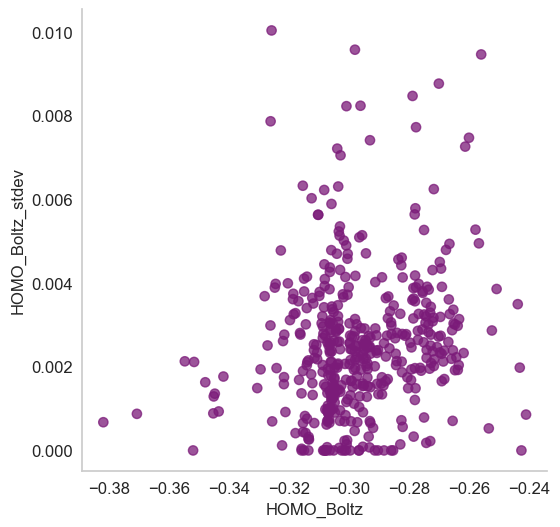

In [11]:

feature_set = pd.DataFrame(feature_df, columns=feature_df.columns)
export_to_excel = False
save_plot_as_png = False
plot_file_name = 'feature_vs_feature_plot.png'
fig_size = fig_size_default

# choose features to plot
feature_x = feature_set.columns[0]
feature_y = feature_set.columns[1]
feature_z = None

#### --- Choose plot parameters --- ###
alpha = marker_alpha_default
color = '#7B1B79'
edge_color = None
marker = 'o'
size = marker_size_default
ax_font_size = fig_font_size
title_font_size = fig_title_size
plot_title = None

subgroup = False
subgroup_column_name = None
subgroup_palette = None
color_dictionary = None

heatmap = False
response_column = None
heatmap_palette = 'plasma'
#_______________________________________________________________________________
#_______________________________________________________________________________

feat_df = cf.feat_v_feat(feature_set, ID, smiles, feature_x, feature_y, feature_z)

feat_fig, feat_ax = cf.plot_chemical_space(
    df=feat_df, x=feature_x, y=feature_y, z=feature_z, fig_size=fig_size,
    xlabel=feature_x, ylabel=feature_y, zlabel=feature_z,
    marker_size=size, marker_color=color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
    marker_edge_width=1, title=plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
    fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup,
    subgroup_column_name=subgroup_column_name, subgroup_palette=subgroup_palette,
    category_dict=color_dictionary, heatmap=heatmap, response_column_name=response_column,
    heatmap_palette=heatmap_palette, input_df=feature_input_df, threedim=(feature_z is not None)
)


### Plot Interactive Chemical Space

This cell launches a Dash application on the configured port. Choose a different port if that port is already in use.

In [12]:

df = umap_df
x_coordinates = 'UMAP1'
y_coordinates = 'UMAP2'
id_column = 'id'
smiles_column = 'smiles'

# stylize markers
alpha = marker_alpha_default
color = '#7B1B79'
marker = 'circle'
size = 10
linewidth = 1
linecolor = 'black'

# if you want to stylize markers by a response variable
size_column = None
alpha_column = None
marker_column = None

# stylize figure
title = 'Chemical Space Map (UMAP)'
x_label = 'UMAP1'
y_label = 'UMAP2'
fig_width = 600
fig_height = 600

###### -------- if you want to plot subgroups -------- ######
subgroup = False
subgroup_col = 'type'
subgroup_palette = None
categorical = True
category_dict = None
categorical_palette = None

###### -------- if you want to plot compounds of interest -------- ######
overlay_col = None
overlay_marker = 'diamond'
overlay_color_dict = None
overlay_plot_dict = None

#_______________________________________________________________________________
#_______________________________________________________________________________

int_plot = cf.int_scatter_dash(
    df, x_col=x_coordinates, y_col=y_coordinates,
    smiles_col=smiles_column, id_col=id_column, molSize=(150, 150),
    marker_size=size, marker_symbol=marker, marker_color=color,
    marker_alpha=alpha, linewidth=linewidth, lincolor=linecolor,
    plot_title=title, x_label=x_label, y_label=y_label, fig_width=fig_width, fig_height=fig_height,
    subgroup=subgroup, subgroup_col=subgroup_col, subgroup_palette=subgroup_palette,
    categorical=categorical, category_dict=category_dict, categorical_palette=categorical_palette,
    overlay_col=overlay_col, overlay_color_dict=overlay_color_dict,
    overlay_plot_dict=overlay_plot_dict, overlay_marker=overlay_marker,
    size_col=size_column, min_size=1, max_size=20,
    alpha_col=alpha_column, min_alpha=0.5, max_alpha=1.0,
    marker_col=marker_column, debug=False
)


# Clustering Techniques

### Choose Number of Clusters (Optional)

Clustering is performed on the selected two-dimensional embedding, not on the original descriptor matrix. AIC and BIC are intended for probabilistic models such as GMM, whereas inertia is primarily useful for K-means.

/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


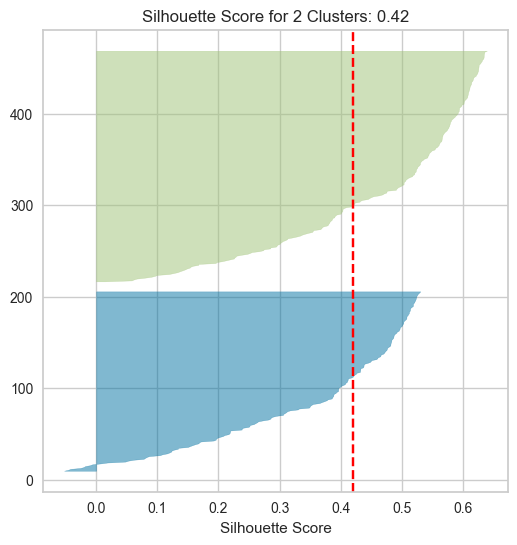

/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


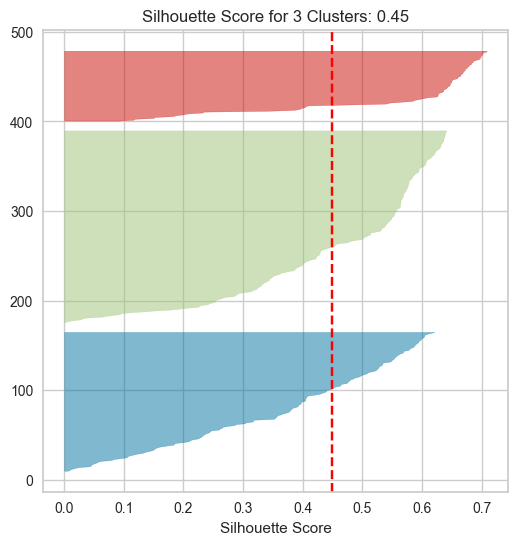

/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


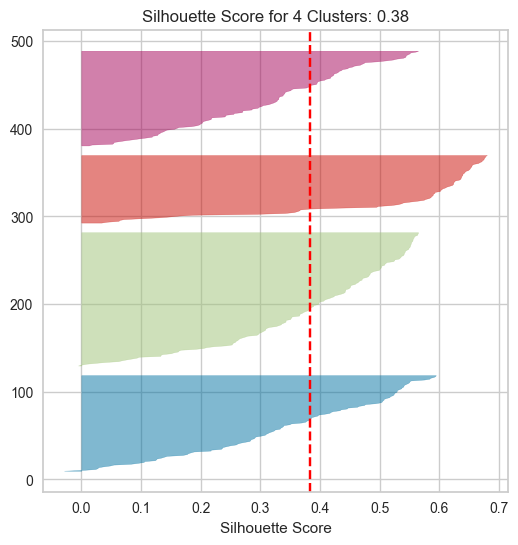

/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


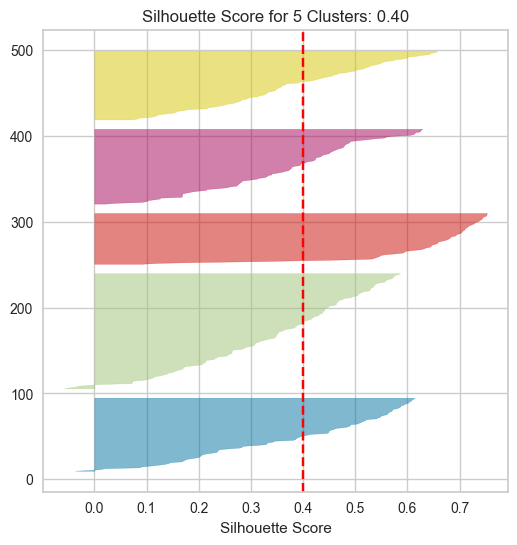

/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


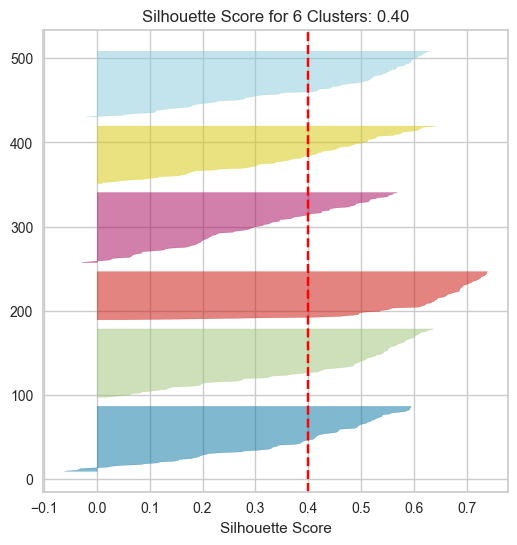

/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


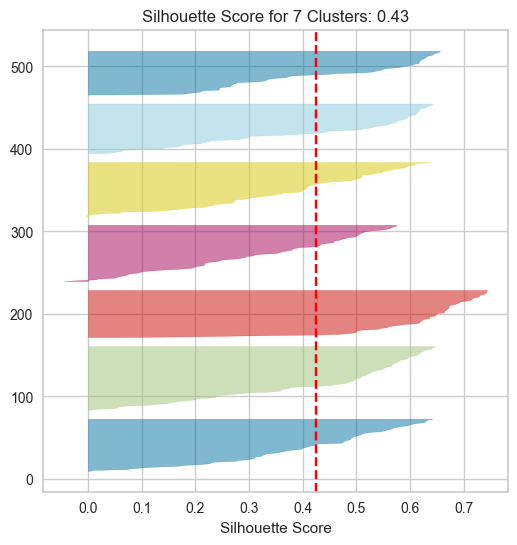

/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


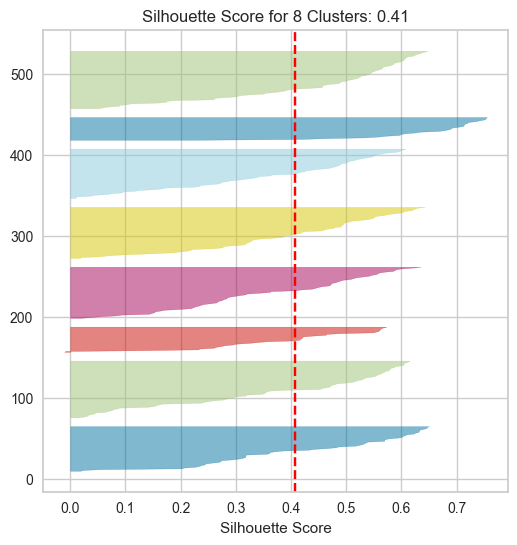

/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


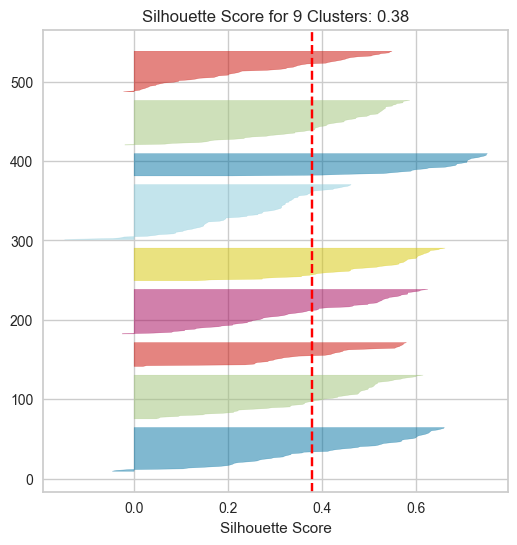

/home/pbianchi/micromamba/envs/chem_env/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


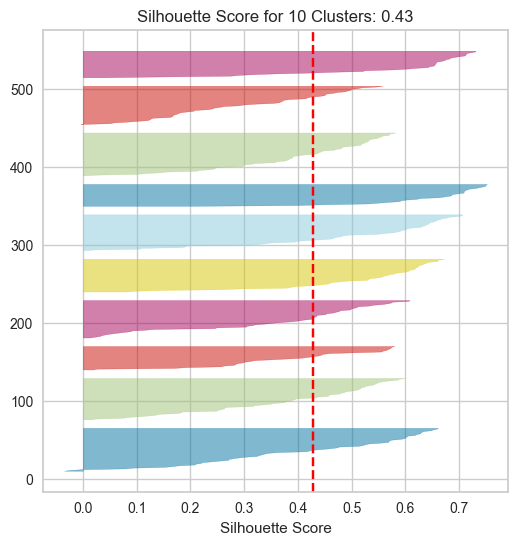

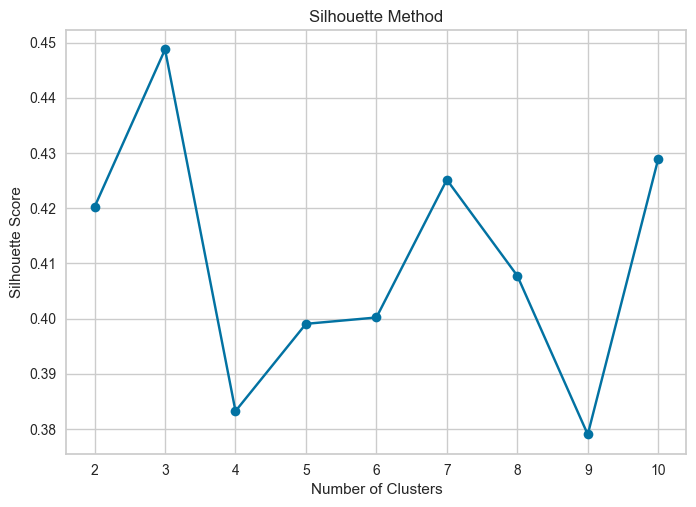

In [13]:
# see silhouette scores for different numbers of clusters
# ideal plot: clusters have above average silhouette scores, size of the silhouette plots are similar 
# and thickness of the plot for each cluster is uniform
# higher score (up to 1) indicates better clustering
# The selected scoring method must be compatible with the chosen clustering algorithm.

scoring_method = 'silhouette_scores' #options: silhouette_scores, aic_bic_scores, elbow_method

df = umap_df
X_coordinate_column = 'UMAP1'
Y_coordinate_column = 'UMAP2'

random_state = 42
min_clusters = 2
max_clusters = 10
clustering_algorithm = cf.kmeans_clustering

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
if scoring_method == 'silhouette_scores':
    silhouette_scoring = cf.silhouette_scores(df, X_coordinate_column, Y_coordinate_column, min_clusters, max_clusters, clustering_algorithm, random_state)
elif scoring_method == 'aic_bic_scores':
    aic_scoring = cf.aic_bic_inertia_scores(df, X_coordinate_column, Y_coordinate_column, min_clusters, max_clusters, clustering_algorithm, random_state)  
elif scoring_method == 'elbow_method':
    elbow_method = cf.elbow_method(df, X_coordinate_column, Y_coordinate_column, min_clusters, max_clusters, clustering_algorithm, random_state)
else:
    print('Invalid scoring method')


### Choose Clustering Algorithm

In [14]:

df = umap_df
X_coordinate_column = 'UMAP1'
Y_coordinate_column = 'UMAP2'
random_state = 42

# subgroup settings shared by clustering plots
subgroup_plot_dict = {'tested': 'plot', 'untested': 'skip'}


#### HDBSCAN

HDBSCAN assigns cluster label `-1` to points classified as noise.

##### Screen HDBSCAN parameters (optional)

Inspect the number of clusters and fraction assigned across parameter combinations.

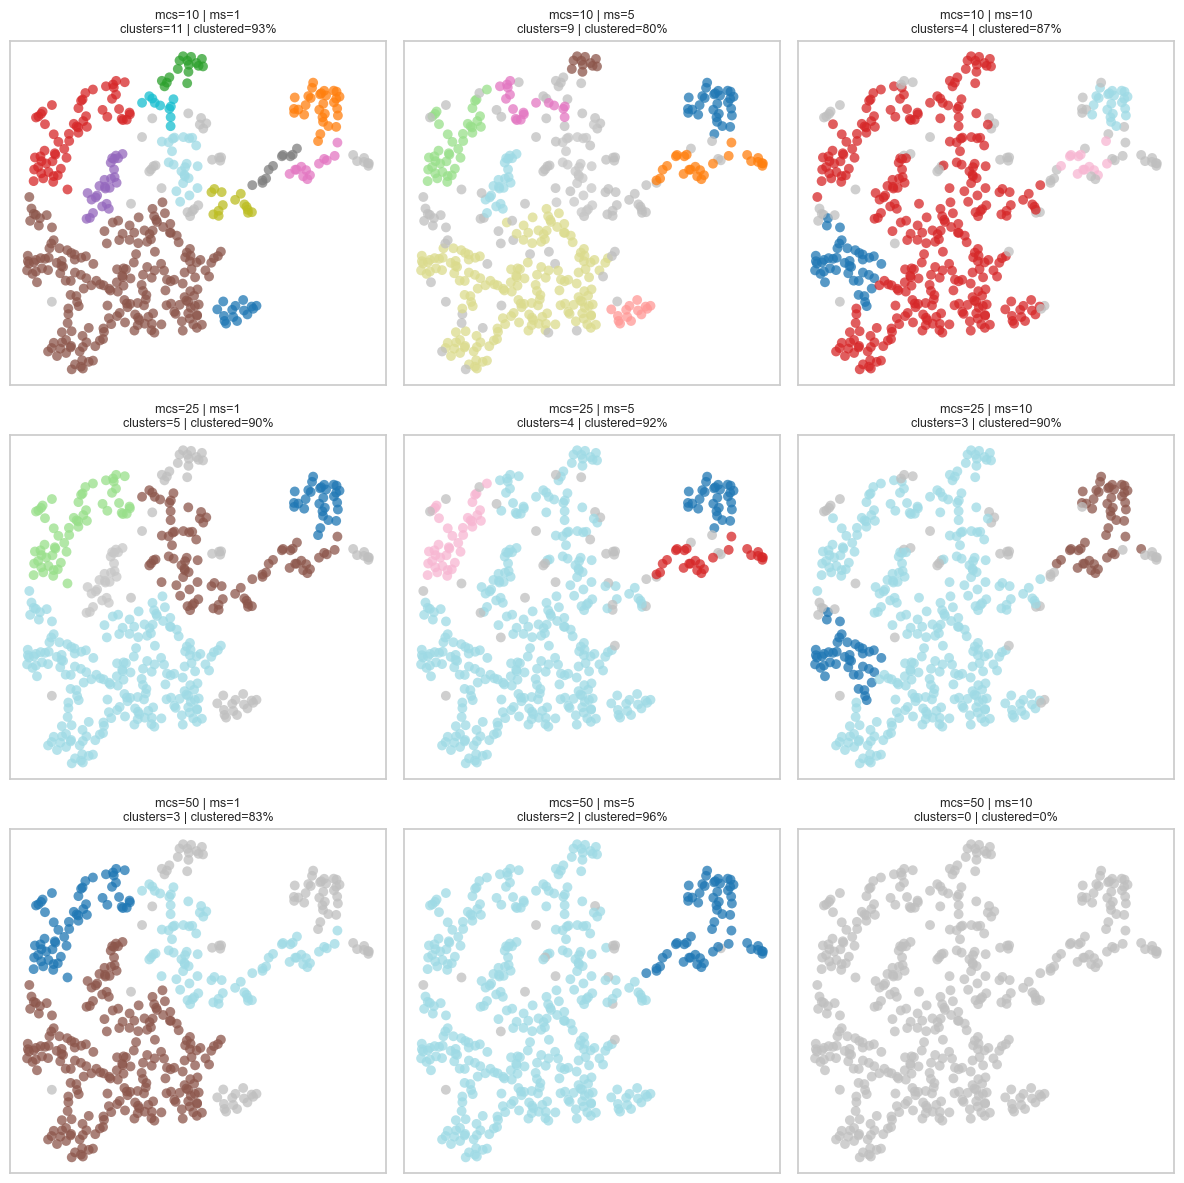

,min_cluster_size,min_samples,n_clusters,fraction_clustered
0,10,1,11,0.933333
1,10,5,9,0.795556
2,10,10,4,0.868889
3,25,1,5,0.897778
4,25,5,4,0.924444
5,25,10,3,0.900000
6,50,1,3,0.831111
7,50,5,2,0.964444
8,50,10,0,0.000000


In [15]:

screen_results, screen_fig = cf.screen_hdbscan_parameters(
    df=df,
    x=X_coordinate_column,
    y=Y_coordinate_column,
    min_cluster_sizes=[10, 25, 50],
    min_samples_values=[1, 5, 10],
    distance_metric='euclidean',
    max_cluster_size=0,
    fig_size=(4, 4),
    marker_size=50,
    alpha=marker_alpha_default,
    cmap='tab20',
    save_plot=False,
    plot_filename='hdbscan_parameter_screen.png'
)

screen_results


Fraction of points clustered: 0.9333333333333333


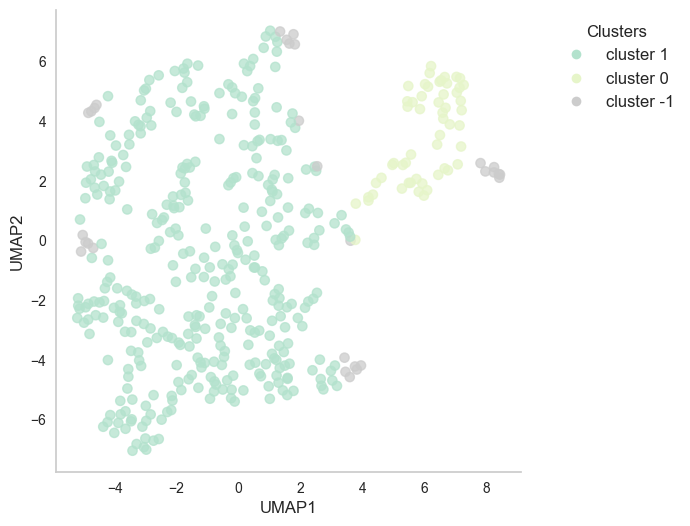

In [16]:

min_cluster_size = 25
min_samples = 15
distance_metric = 'euclidean'
max_cluster_size = 0

export_to_excel = False
save_plot_as_png = False
excel_file_name = 'hdbscan_clusters_and_coordinates.xlsx'
plot_file_name = 'hdbscan_clusters_plot.png'

#### --- Choose plot parameters --- ###
alpha = marker_alpha_default
edge_color = None
cluster_color_map = 'Pastel2'
color = '#d3d3d3'
marker = 'o'
size = marker_size_default
size_col_name = None
ax_font_size = fig_font_size
title_font_size = fig_title_size
plot_title = None
fig_size = fig_size_default

# If you want to plot subsets of data points in addition to HDBSCAN clusters
subgroup = False
subgroup_column_name = 'type'
subgroup_marker = 'D'
subgroup_palette = None
color_dictionary = None
#_______________________________________________________________________________
#_______________________________________________________________________________

hdbscan_clusters, hdbscan_clusters_df = cf.hdbscan_clustering(
    df, X_coordinate_column, Y_coordinate_column, random_state,
    min_cluster_size, min_samples, distance_metric, max_cluster_size
)

if export_to_excel:
    hdbscan_clusters_df.to_excel(excel_file_name, index=False)
    print(f'HDBSCAN results exported to {excel_file_name}')

hdbscan_plot = cf.cluster_plots(
    df=hdbscan_clusters_df, x=X_coordinate_column, y=Y_coordinate_column, cluster_column='cluster',
    cluster_color_map=cluster_color_map, xlabel=X_coordinate_column, ylabel=Y_coordinate_column,
    marker_size=size, marker_color=color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
    title=plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
    fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup,
    subgroup_column_name=subgroup_column_name, subgroup_palette=subgroup_palette,
    color_dictionary=color_dictionary, size_col_name=size_col_name, fig_size=fig_size,
    subgroup_plot_dict=subgroup_plot_dict, subgroup_marker=subgroup_marker, hdbscan_cartoon=False
)


#### DBSCAN

DBSCAN assigns cluster label `-1` to points classified as noise.

Fraction of points clustered: 0.82


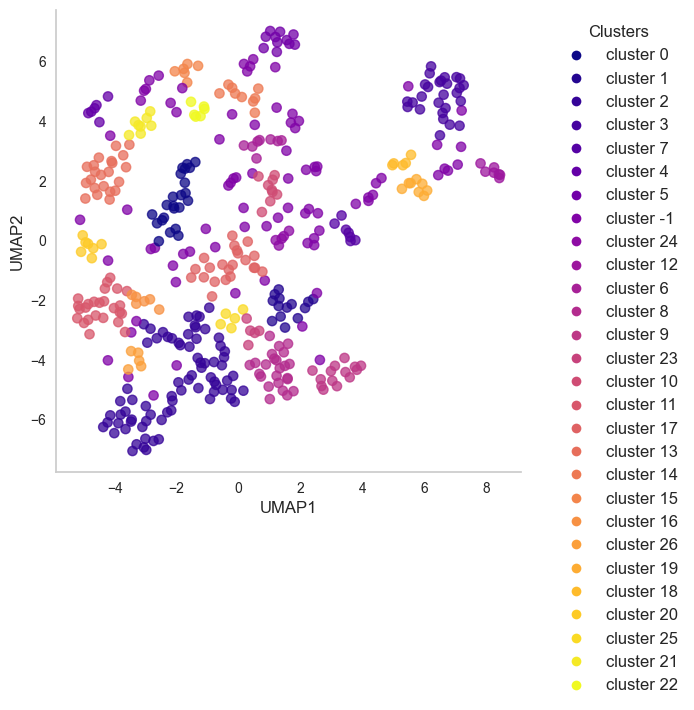

In [17]:

eps = 0.5
min_samples = 5
distance_metric = 'euclidean'

export_to_excel = False
save_plot_as_png = False
excel_file_name = 'dbscan_clusters_and_coordinates.xlsx'
plot_file_name = 'dbscan_clusters_plot.png'

alpha = marker_alpha_default
edge_color = None
cluster_color_map = 'plasma'
marker = 'o'
size = marker_size_default
ax_font_size = fig_font_size
title_font_size = fig_title_size
plot_title = None
fig_size = fig_size_default

subgroup = False
subgroup_column_name = 'type'
subgroup_marker = 'D'
subgroup_palette = None
color_dictionary = None
#_______________________________________________________________________________
#_______________________________________________________________________________

dbscan_clusters, dbscan_clusters_df = cf.dbscan_clustering(
    df, X_coordinate_column, Y_coordinate_column, random_state,
    distance_metric=distance_metric, eps=eps, min_samples=min_samples
)

if export_to_excel:
    dbscan_clusters_df.to_excel(excel_file_name, index=False)
    print(f'DBSCAN results exported to {excel_file_name}')

dbscan_plot = cf.cluster_plots(
    df=dbscan_clusters_df, x=X_coordinate_column, y=Y_coordinate_column, cluster_column='cluster',
    cluster_color_map=cluster_color_map, xlabel=X_coordinate_column, ylabel=Y_coordinate_column,
    marker_size=size, marker_color='#7B1B79', alpha=alpha, marker=marker, marker_edge_color=edge_color,
    title=plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
    fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup,
    subgroup_column_name=subgroup_column_name, subgroup_palette=subgroup_palette,
    size_col_name=None, fig_size=fig_size, subgroup_plot_dict=subgroup_plot_dict,
    subgroup_marker=subgroup_marker, color_dictionary=color_dictionary
)


#### K-Means Clustering

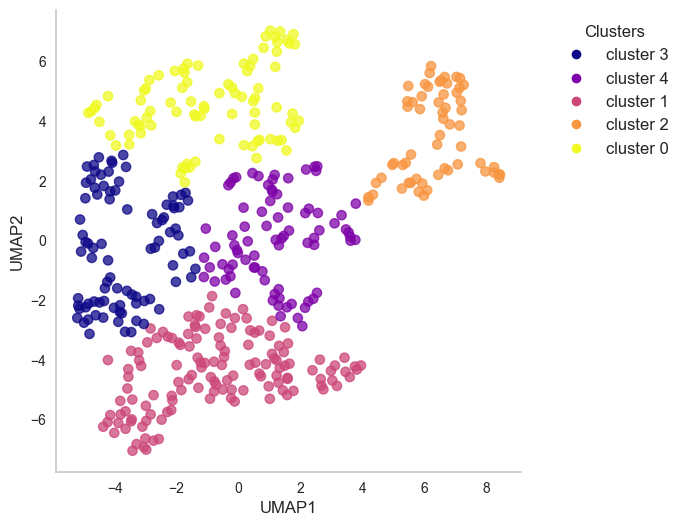

In [18]:

# number of clusters should be selected using one of the methods above
n_clusters = 5

export_to_excel = False
save_plot_as_png = False
excel_file_name = 'kmeans_clusters_and_coordinates.xlsx'
plot_file_name = 'kmeans_clusters_plot.png'

alpha = marker_alpha_default
edge_color = None
cluster_color_map = 'plasma'
marker = 'o'
size = marker_size_default
ax_font_size = fig_font_size
title_font_size = fig_title_size
plot_title = None
fig_size = fig_size_default

subgroup = False
subgroup_column_name = 'type'
subgroup_marker = 'D'
subgroup_palette = None
color_dictionary = None
#_______________________________________________________________________________
#_______________________________________________________________________________

kmeans_clusters, kmeans_clusters_df = cf.kmeans_clustering(df, X_coordinate_column, Y_coordinate_column, random_state, n_clusters)

if export_to_excel:
    kmeans_clusters_df.to_excel(excel_file_name, index=False)
    print(f'KMeans results exported to {excel_file_name}')

kmeans_plot = cf.cluster_plots(
    df=kmeans_clusters_df, x=X_coordinate_column, y=Y_coordinate_column, cluster_column='cluster',
    cluster_color_map=cluster_color_map, xlabel=X_coordinate_column, ylabel=Y_coordinate_column,
    marker_size=size, marker_color='#7B1B79', alpha=alpha, marker=marker, marker_edge_color=edge_color,
    title=plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
    fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup,
    subgroup_column_name=subgroup_column_name, subgroup_palette=subgroup_palette,
    size_col_name=None, fig_size=fig_size, subgroup_plot_dict=subgroup_plot_dict,
    subgroup_marker=subgroup_marker, color_dictionary=color_dictionary
)


#### GMM Clustering

The output includes the probability that each compound belongs to every Gaussian component.

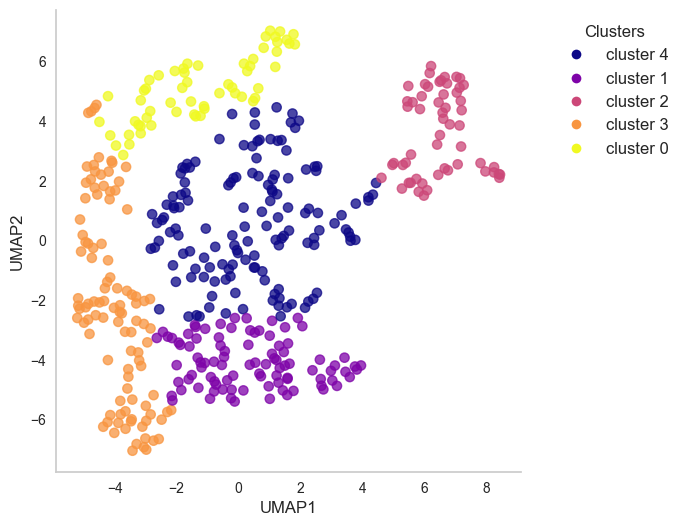

In [19]:

n_clusters = 5
covariance_type = 'full'

export_to_excel = False
save_plot_as_png = False
excel_file_name = 'gmm_clusters_and_coordinates.xlsx'
plot_file_name = 'gmm_clusters_plot.png'

alpha = marker_alpha_default
edge_color = None
cluster_color_map = 'plasma'
marker = 'o'
size = marker_size_default
ax_font_size = fig_font_size
title_font_size = fig_title_size
plot_title = None
fig_size = fig_size_default

subgroup = False
subgroup_column_name = 'type'
subgroup_marker = 'D'
subgroup_palette = None
color_dictionary = None
#_______________________________________________________________________________
#_______________________________________________________________________________

gmm_clusters, gmm_clusters_df = cf.gmm_clustering(df, X_coordinate_column, Y_coordinate_column, random_state, n_clusters, covariance_type)

if export_to_excel:
    gmm_clusters_df.to_excel(excel_file_name, index=False)
    print(f'GMM results exported to {excel_file_name}')

gmm_plot = cf.cluster_plots(
    df=gmm_clusters_df, x=X_coordinate_column, y=Y_coordinate_column, cluster_column='cluster',
    cluster_color_map=cluster_color_map, xlabel=X_coordinate_column, ylabel=Y_coordinate_column,
    marker_size=size, marker_color='#7B1B79', alpha=alpha, marker=marker, marker_edge_color=edge_color,
    title=plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
    fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup,
    subgroup_column_name=subgroup_column_name, subgroup_palette=subgroup_palette,
    size_col_name=None, fig_size=fig_size, subgroup_plot_dict=subgroup_plot_dict,
    subgroup_marker=subgroup_marker, color_dictionary=color_dictionary
)


#### Agglomerative Clustering (Ward Clustering)

Ward linkage requires the Euclidean distance metric.

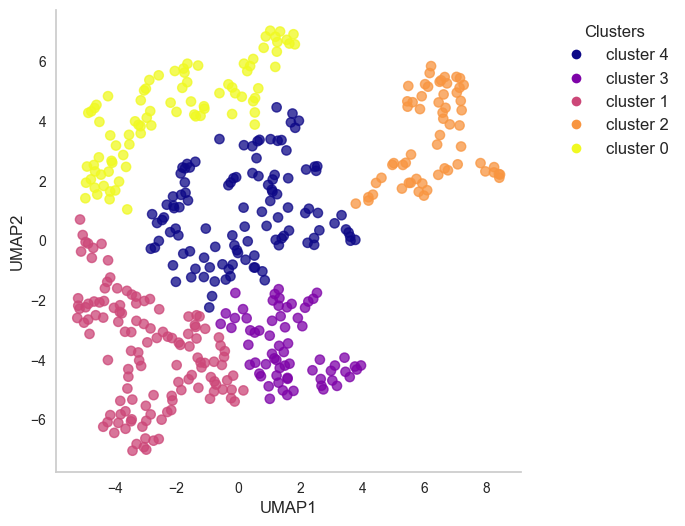

In [20]:

n_clusters = 5
distance_metric = 'euclidean'
linkage_type = 'ward'

alpha = marker_alpha_default
edge_color = None
cluster_color_map = 'plasma'
marker = 'o'
size = marker_size_default
ax_font_size = fig_font_size
title_font_size = fig_title_size
plot_title = None
fig_size = fig_size_default

subgroup = False
subgroup_column_name = 'type'
subgroup_marker = 'D'
subgroup_palette = None
color_dictionary = None
#_______________________________________________________________________________
#_______________________________________________________________________________

agglomerative_clusters, agg_clusters_df = cf.agglomerative_clustering(
    df, X_coordinate_column, Y_coordinate_column, random_state, n_clusters, distance_metric, linkage_type
)

agglomerative_plot = cf.cluster_plots(
    df=agg_clusters_df, x=X_coordinate_column, y=Y_coordinate_column, cluster_column='cluster',
    cluster_color_map=cluster_color_map, xlabel=X_coordinate_column, ylabel=Y_coordinate_column,
    marker_size=size, marker_color='#7B1B79', alpha=alpha, marker=marker, marker_edge_color=edge_color,
    title=plot_title, save_plot=False, plot_filename='agglomerative_clusters_plot.png',
    fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup,
    subgroup_column_name=subgroup_column_name, subgroup_palette=subgroup_palette,
    size_col_name=None, fig_size=fig_size, subgroup_plot_dict=subgroup_plot_dict,
    subgroup_marker=subgroup_marker, color_dictionary=color_dictionary
)


#### BIRCH Clustering

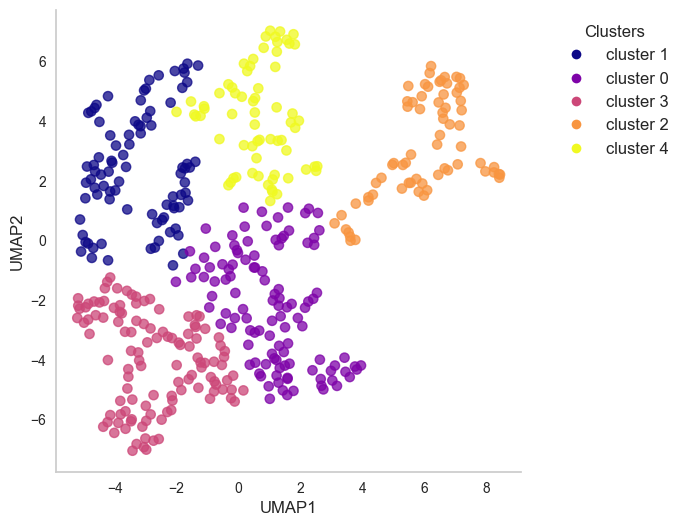

In [21]:

n_clusters = 5
threshold = 0.5
branching_factor = 50

alpha = marker_alpha_default
edge_color = None
cluster_color_map = 'plasma'
marker = 'o'
size = marker_size_default
ax_font_size = fig_font_size
title_font_size = fig_title_size
plot_title = None
fig_size = fig_size_default

subgroup = False
subgroup_column_name = 'type'
subgroup_marker = 'D'
subgroup_palette = None
color_dictionary = None
#_______________________________________________________________________________
#_______________________________________________________________________________

birch_clusters, birch_clusters_df = cf.BIRCH_clustering(
    df, X_coordinate_column, Y_coordinate_column, random_state, n_clusters, threshold, branching_factor
)

birch_plot = cf.cluster_plots(
    df=birch_clusters_df, x=X_coordinate_column, y=Y_coordinate_column, cluster_column='cluster',
    cluster_color_map=cluster_color_map, xlabel=X_coordinate_column, ylabel=Y_coordinate_column,
    marker_size=size, marker_color='#7B1B79', alpha=alpha, marker=marker, marker_edge_color=edge_color,
    title=plot_title, save_plot=False, plot_filename='birch_clusters_plot.png',
    fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup,
    subgroup_column_name=subgroup_column_name, subgroup_palette=subgroup_palette,
    size_col_name=None, fig_size=fig_size, subgroup_plot_dict=subgroup_plot_dict,
    subgroup_marker=subgroup_marker, color_dictionary=color_dictionary
)


### Interactive Plot with Clusters

In [22]:

df = hdbscan_clusters_df
x_coordinates = X_coordinate_column
y_coordinates = Y_coordinate_column
id_column = 'id'
smiles_column = 'smiles'

# stylize markers
alpha = 1
color = '#d3d3d3'
marker = 'circle'
size = 10
linewidth = 0
linecolor = None

# if you want to stylize markers by a response variable
size_column = None
alpha_column = None
marker_column = None

# stylize figure
title = 'UMAP with HDBSCAN clustering'
x_label = X_coordinate_column
y_label = Y_coordinate_column
fig_width = 600
fig_height = 600

###### -------- if you want to plot clusters -------- ######
subgroup = True
subgroup_col = 'cluster'
subgroup_palette = None
categorical = True
category_dict = None
categorical_palette = 'Pastel2'

###### -------- if you want to plot compounds of interest -------- ######
overlay_col = None
overlay_marker = 'diamond'
overlay_color_dict = None
overlay_plot_dict = None

#_______________________________________________________________________________
#_______________________________________________________________________________

int_plot = cf.int_scatter_dash(
    df, x_col=x_coordinates, y_col=y_coordinates,
    smiles_col=smiles_column, id_col=id_column, molSize=(150, 150),
    marker_size=size, marker_symbol=marker, marker_color=color,
    marker_alpha=alpha, linewidth=linewidth, lincolor=linecolor,
    plot_title=title, x_label=x_label, y_label=y_label, fig_width=fig_width, fig_height=fig_height,
    subgroup=subgroup, subgroup_col=subgroup_col, subgroup_palette=subgroup_palette,
    categorical=categorical, category_dict=category_dict, categorical_palette=categorical_palette,
    overlay_col=overlay_col, overlay_color_dict=overlay_color_dict,
    overlay_plot_dict=overlay_plot_dict, overlay_marker=overlay_marker,
    size_col=size_column, min_size=1, max_size=20,
    alpha_col=alpha_column, min_alpha=0.5, max_alpha=1.0,
    marker_col=marker_column, debug=False
)


HOVER DATA: {'curveNumber': 1, 'pointNumber': 46, 'pointIndex': 46, 'x': 5.993875980377197, 'y': 1.5087140798568726, 'hovertext': ' ', 'marker.symbol': 'circle', 'marker.opacity': 1, 'marker.size': 10, 'xPixel': 371.48, 'yPixel': 270.74, 'bbox': {'x0': 374.48, 'x1': 384.48, 'y0': 273.74, 'y1': 283.74}}
HOVER DATA: {'curveNumber': 0, 'pointNumber': 213, 'pointIndex': 213, 'x': -5.119131088256836, 'y': 0.7075860500335693, 'hovertext': ' ', 'marker.symbol': 'circle', 'marker.opacity': 1, 'marker.size': 10, 'xPixel': 107.11, 'yPixel': 291.55, 'bbox': {'x0': 110.11, 'x1': 120.11, 'y0': 294.55, 'y1': 304.55}}
HOVER DATA: {'curveNumber': 0, 'pointNumber': 184, 'pointIndex': 184, 'x': -3.59373140335083, 'y': 1.045762538909912, 'hovertext': ' ', 'marker.symbol': 'circle', 'marker.opacity': 1, 'marker.size': 10, 'xPixel': 143.4, 'yPixel': 282.77, 'bbox': {'x0': 146.4, 'x1': 156.4, 'y0': 285.77, 'y1': 295.77}}
HOVER DATA: {'curveNumber': 0, 'pointNumber': 333, 'pointIndex': 333, 'x': -4.424149036